# Análise Epidemiológica e Distribuição de Vacinas em Destaque

**Projeto:** PyAnalytics — UFSC Araranguá

**Autoras:** Beatriz Goulart e Esther de Oliveira  

**Arquivo de Origem:** `vacinas_analitico.csv`  

---

## Contexto e Objetivos

A análise dos registros de vacinação permite identificar quais imunizantes apresentam maior ou menor participação na base e compreender como essa distribuição se comporta de acordo com diferentes dimensões, como período, estratégia, dose e território.

Esta análise busca destacar os principais imunizantes presentes na base e organizar sua distribuição de forma que facilite a interpretação dos registros de vacinação, permitindo:

1. Identificar quais vacinas apresentam maior volume de aplicações registradas.
2. Comparar a participação dos imunizantes por diferentes medidas e recortes.
3. Verificar se a posição das vacinas se modifica conforme o período e a estratégia.
4. Avaliar se os registros estão concentrados em poucos imunizantes ou distribuídos de forma mais equilibrada.
5. Preservar diferenças entre apresentações, estratégias e doses para evitar agrupamentos inadequados.

## Bibliotecas e configuração

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_colwidth", None)


## Carregamento da base

In [2]:
from pathlib import Path

caminhos = [
    Path("../../data/processed/vacinas_analitico.csv"),
    Path("../data/processed/vacinas_analitico.csv"),
    Path("data/processed/vacinas_analitico.csv"),
    Path("vacinas_analitico.csv")
]

file_path = next((caminho for caminho in caminhos if caminho.exists()), None)

if file_path is None:
    raise FileNotFoundError("O arquivo não foi encontrado.")

df = pd.read_csv(file_path)

print(f"Arquivo utilizado: {file_path}")
display(df.head())


Arquivo utilizado: ..\..\data\processed\vacinas_analitico.csv


,nome_do_bairro,nome_da_vacina,codigo_da_vacina,estrategia,codigo_da_estrategia,dose,codigo_da_dose,vacina_estrategia_e_dose,lote,validade_do_lote,data_da_aplicacao,origem
0,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
1,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
2,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
3,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
4,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação


## Estrutura da base

In [3]:
print(f"Registros: {df.shape[0]:,}".replace(",", "."))
print(f"Colunas: {df.shape[1]}")

display(pd.DataFrame({
    "Coluna": df.columns,
    "Tipo": df.dtypes.astype(str).values,
    "Valores ausentes": df.isna().sum().values,
    "Valores distintos": [df[col].nunique(dropna=True) for col in df.columns]
}))

display(df.head())


Registros: 30.883
Colunas: 12


,Coluna,Tipo,Valores ausentes,Valores distintos
0,nome_do_bairro,str,0,15
1,nome_da_vacina,str,0,41
2,codigo_da_vacina,int64,0,33
3,estrategia,str,0,12
4,codigo_da_estrategia,int64,0,9
5,dose,str,9,27
6,codigo_da_dose,float64,9,23
7,vacina_estrategia_e_dose,str,0,163
8,lote,str,0,271
9,validade_do_lote,str,0,101


,nome_do_bairro,nome_da_vacina,codigo_da_vacina,estrategia,codigo_da_estrategia,dose,codigo_da_dose,vacina_estrategia_e_dose,lote,validade_do_lote,data_da_aplicacao,origem
0,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
1,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
2,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
3,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
4,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) - Rotina (1) - REVACINAÇÃO (10)",MT7306,17/04/2026,02/04/2026,Tela de Aplicação


## Qualidade dos dados

In [4]:
qualidade = pd.DataFrame({
    "Indicador": [
        "Registros",
        "Colunas",
        "Registros duplicados",
        "Células ausentes"
    ],
    "Valor": [
        len(df),
        df.shape[1],
        int(df.duplicated().sum()),
        int(df.isna().sum().sum())
    ]
})

display(qualidade)

ausentes = (
    df.isna()
    .sum()
    .sort_values(ascending=False)
    .rename_axis("Coluna")
    .reset_index(name="Valores ausentes")
)

display(ausentes.head(15))


,Indicador,Valor
0,Registros,30883
1,Colunas,12
2,Registros duplicados,23209
3,Células ausentes,1738


,Coluna,Valores ausentes
0,origem,860
1,data_da_aplicacao,860
2,codigo_da_dose,9
3,dose,9
4,estrategia,0
5,codigo_da_vacina,0
6,nome_da_vacina,0
7,nome_do_bairro,0
8,vacina_estrategia_e_dose,0
9,codigo_da_estrategia,0


## Tratamento da data

In [5]:
df["data_da_aplicacao"] = pd.to_datetime(
    df["data_da_aplicacao"],
    dayfirst=True,
    errors="coerce"
)

df["ano"] = df["data_da_aplicacao"].dt.year
df["mes"] = df["data_da_aplicacao"].dt.to_period("M").astype("string")

print("Período inicial:", df["data_da_aplicacao"].min())
print("Período final:", df["data_da_aplicacao"].max())
print("Datas inválidas:", int(df["data_da_aplicacao"].isna().sum()))

display(
    df[["data_da_aplicacao", "ano", "mes"]]
    .head()
)


Período inicial: 2026-02-01 00:00:00
Período final: 2026-06-30 00:00:00
Datas inválidas: 860


,data_da_aplicacao,ano,mes
0,2026-04-02,2026.0,2026-04
1,2026-04-02,2026.0,2026-04
2,2026-04-02,2026.0,2026-04
3,2026-04-02,2026.0,2026-04
4,2026-04-02,2026.0,2026-04


In [6]:
df["estrategia"] = df["estrategia"].astype("string").str.strip()
df["estrategia"] = df["estrategia"].replace({
    "Rotina (1)": "Rotina",
    "Pós": "Pós-exposição",
    "Monitoramento das Estratégias de Vacinação": "MEV"
})

df["dose"] = df["dose"].astype("string").str.strip()
df["dose"] = df["dose"].replace({
    "PROFILAXIA/TRATAMENTO COM 1 FRASCO-AMPOLA/AMPOLA": "PROFILAXIA/TRATAMENTO"
})

def rotulo_vacina(nome):
    if pd.isna(nome):
        return "Não informado"
    nome = re.sub(r"^Vacina\s+", "", str(nome).strip(), flags=re.IGNORECASE)
    nome = re.sub(r"\s+", " ", nome)
    nome = nome.replace("COVID-19-RNAm, ", "COVID-19 ")
    nome = nome.replace("COVID-19-RNAm,", "COVID-19")
    return nome.strip()

def rotulo_estrategia(nome):
    if pd.isna(nome):
        return "Não informado"
    return {
        "Rotina (1)": "Rotina",
        "Pós": "Pós-exposição",
        "Monitoramento das Estratégias de Vacinação": "MEV"
    }.get(str(nome).strip(), str(nome).strip())

print("Categorias normalizadas.")
print("Legenda: MEV = Monitoramento das Estratégias de Vacinação.")

Categorias normalizadas.
Legenda: MEV = Monitoramento das Estratégias de Vacinação.


In [7]:
vacinas = (
    df["nome_da_vacina"]
    .value_counts(dropna=False)
    .rename_axis("Vacina_original")
    .reset_index(name="Aplicações")
)
vacinas["Imunizante"] = vacinas["Vacina_original"].map(rotulo_vacina)
vacinas["Percentual (%)"] = vacinas["Aplicações"] / len(df) * 100
display(vacinas[["Imunizante", "Aplicações", "Percentual (%)"]].head(15))

,Imunizante,Aplicações,Percentual (%)
0,influenza trivalente,15809,51.189975
1,difteria e tétano adulto,1608,5.206748
2,hepatite B,1274,4.125247
3,dengue (atenuada),1244,4.028106
4,polio injetável (inativada poliomielite),1197,3.875919
5,febre amarela,930,3.011365
6,"sarampo, caxumba, rubéola",924,2.991937
7,penta (DTP/HepB/Hib),829,2.684325
8,pneumo 10,810,2.622802
9,meningo ACWY,699,2.263381


## Ranking das vacinas

Os gráficos abaixo apresentam o panorama dos imunizantes mais aplicados, detalhando tanto o volume absoluto de doses aplicadas quanto a participação percentual de cada vacina no total analisado.

*Destaque absoluto:* A influenza trivalente lidera de forma expressiva o ranking, registrando 15.809 aplicações, o que representa isoladamente 51,2% de toda a participação demonstrada. Isso reflete o forte impacto das campanhas sazonais de vacinação contra a gripe.
*Demais imunizantes de maior cobertura:* Logo em seguida, destacam-se a vacina de difteria e tétano adulto (1.608 aplicações / 5.2%), hepatite B (1.274 aplicações / 4.1%) e dengue (atenuada) (1.244 aplicações / 4.0%).

*Demanda intermediária e complementar:* As demais posições são compostas por imunizantes fundamentais do calendário de rotina, com volumes que variam entre 699 e 1.197 doses (2,3% a 3,9%), englobando vacinas como pólio inativada, febre amarela, tríplice viral (sarampo, caxumba e rubéola), penta, pneumo 10 e meningo ACWY. 

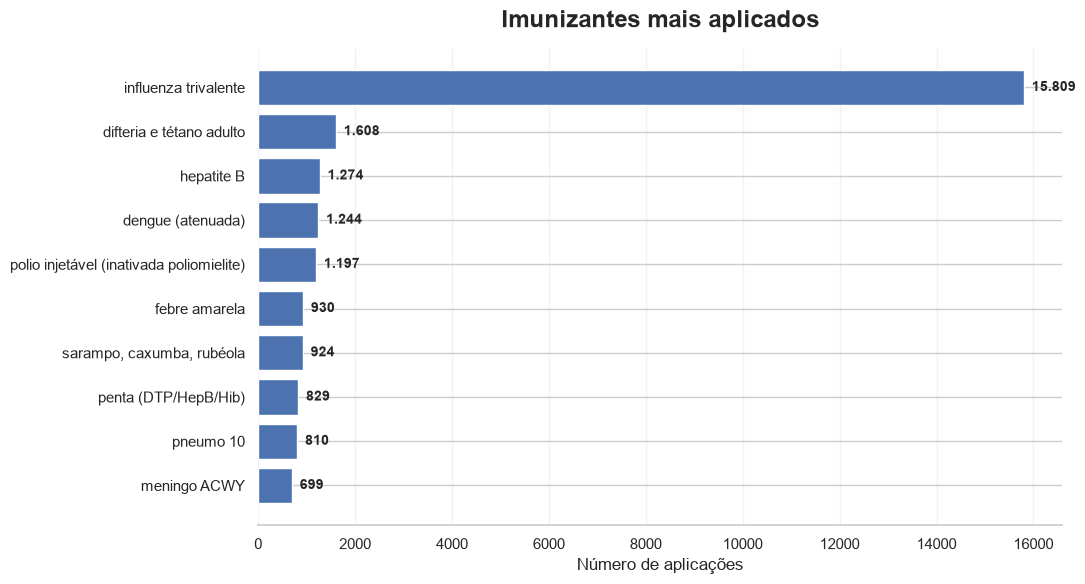

In [8]:
top_vacinas = vacinas.head(10).sort_values("Aplicações")

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(
    top_vacinas["Imunizante"].astype(str),
    top_vacinas["Aplicações"]
)

ax.set_title("Imunizantes mais aplicados", fontsize=17, fontweight="bold", pad=15)
ax.set_xlabel("Número de aplicações")
ax.set_ylabel("")

for bar, valor in zip(bars, top_vacinas["Aplicações"]):
    ax.text(
        bar.get_width() + top_vacinas["Aplicações"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{valor:,}".replace(",", "."),
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


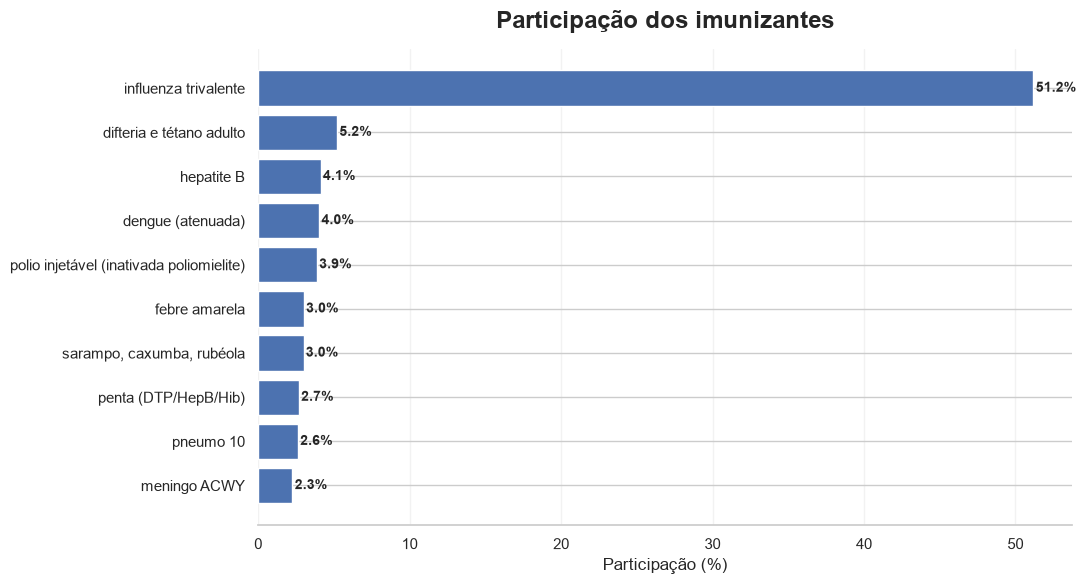

In [9]:
top_percentual = vacinas.head(10).sort_values("Percentual (%)")

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(
    top_percentual["Imunizante"].astype(str),
    top_percentual["Percentual (%)"]
)

ax.set_title("Participação dos imunizantes", fontsize=17, fontweight="bold", pad=15)
ax.set_xlabel("Participação (%)")
ax.set_ylabel("")

for bar, valor in zip(bars, top_percentual["Percentual (%)"]):
    ax.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{valor:.1f}%",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


## Concentração das aplicações

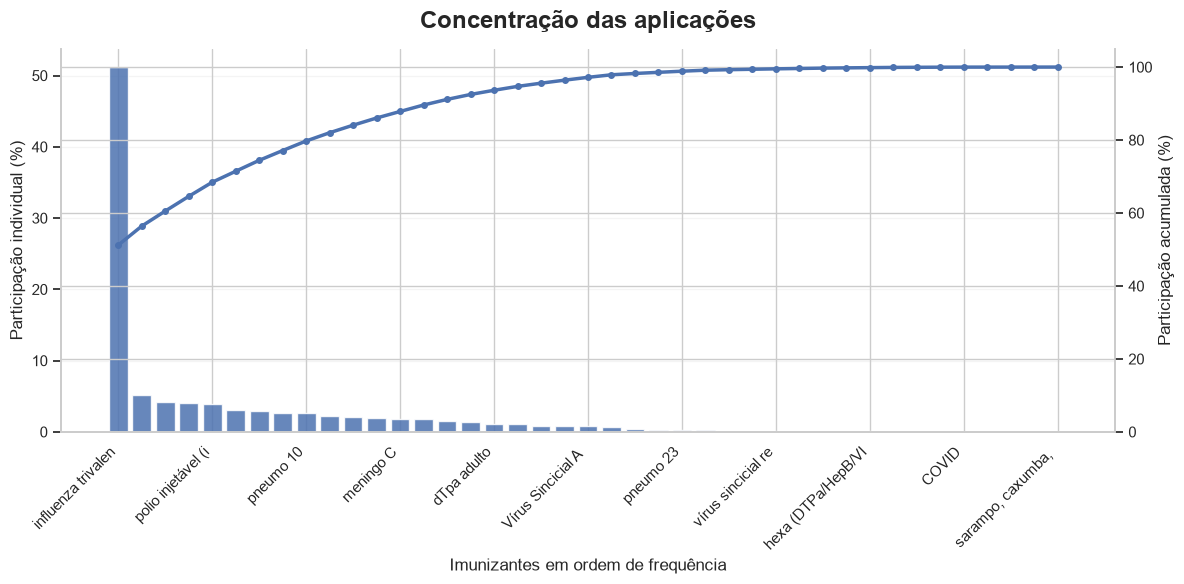

Os 5 imunizantes mais frequentes representam 68.4% dos registros.
Os 10 imunizantes mais frequentes representam 82.0% dos registros.


In [10]:
pareto = vacinas.copy()
pareto["Acumulado (%)"] = pareto["Percentual (%)"].cumsum()

x = np.arange(len(pareto))
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    x,
    pareto["Percentual (%)"],
    alpha=0.85
)

ax1.set_xlabel("Imunizantes em ordem de frequência")
ax1.set_ylabel("Participação individual (%)")
ax1.set_title(
    "Concentração das aplicações",
    fontsize=17,
    fontweight="bold",
    pad=15
)

ax2 = ax1.twinx()

ax2.plot(
    x,
    pareto["Acumulado (%)"],
    marker="o",
    linewidth=2.5,
    markersize=4
)

ax2.set_ylabel("Participação acumulada (%)")
ax2.set_ylim(0, 105)

n = len(pareto)
passo = max(1, n // 10)
indices = list(range(0, n, passo))

ax1.set_xticks(indices)
ax1.set_xticklabels(
    [str(pareto.iloc[i]["Imunizante"])[:18] for i in indices],
    rotation=45,
    ha="right"
)

ax1.grid(axis="y", alpha=0.2)
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Os 5 imunizantes mais frequentes representam {pareto.head(5)['Percentual (%)'].sum():.1f}% dos registros.")
print(f"Os 10 imunizantes mais frequentes representam {pareto.head(10)['Percentual (%)'].sum():.1f}% dos registros.")


## Distribuição por estratégia

O gráfico abaixo ilustra a distribuição do volume de doses aplicadas segmentado pelas diferentes estratégias adotadas nos atendimentos.

*Predominância da Rotina:* A estratégia de Rotina lidera de forma absoluta com 22.648 aplicações, representando o maior volume de atendimento no período.

*Relevância das Campanhas Especiais:* Logo em seguida, a estratégia Especial destaca-se com 7.791 aplicações, configurando o segundo maior eixo de distribuição de doses.

*Demais Estratégias:* As demais categorias, como Pós-exposição (245 aplicações), Intensificação (168 aplicações) e outras modalidades complementares como Pré-exposição, Vacinação Escolar, Campanha indiscriminada, 19, MEV e Bloqueio, apresentam volumes residuais ou pontuais de doses aplicadas.

,Estratégia,Aplicações,Percentual (%)
0,Rotina,22648,73.334844
1,Especial,7791,25.227471
2,Pós-exposição,245,0.793317
3,Intensificação,168,0.543989
4,Pré-exposição,10,0.03238
5,Vacinação Escolar,6,0.019428
6,Campanha indiscriminada,5,0.01619
7,19,5,0.01619
8,MEV,4,0.012952
9,Bloqueio,1,0.003238


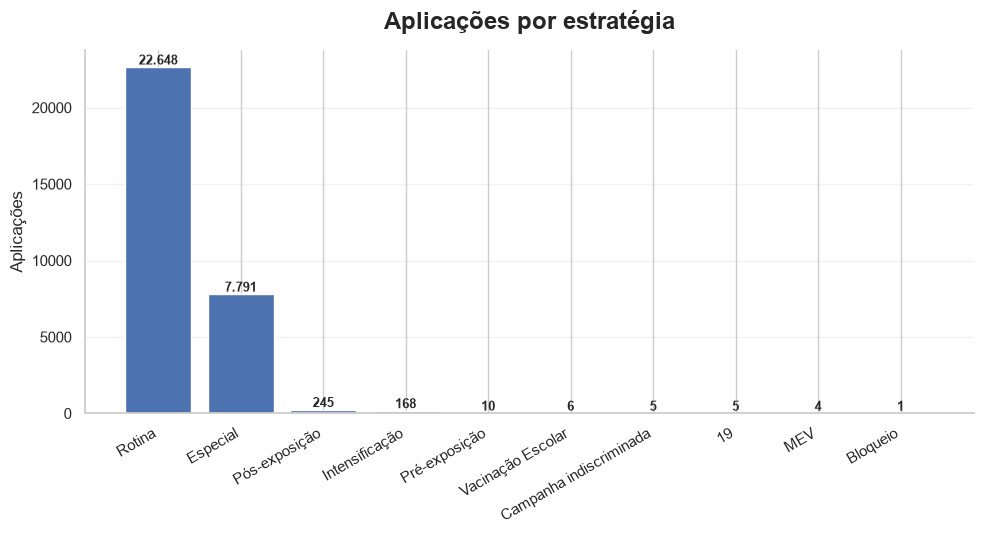

In [11]:
estrategias = (
    df["estrategia"]
    .value_counts(dropna=False)
    .rename_axis("Estratégia")
    .reset_index(name="Aplicações")
)

estrategias["Percentual (%)"] = estrategias["Aplicações"] / len(df) * 100

display(estrategias)

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    estrategias["Estratégia"].astype(str),
    estrategias["Aplicações"]
)

ax.set_title("Aplicações por estratégia", fontsize=17, fontweight="bold", pad=15)
ax.set_ylabel("Aplicações")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")

for bar, valor in zip(bars, estrategias["Aplicações"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{valor:,}".replace(",", "."),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


In [12]:
tabela_vacina_estrategia = pd.crosstab(
    df["nome_da_vacina"],
    df["estrategia"]
)

display(tabela_vacina_estrategia.head(15))


estrategia,19,Bloqueio,Campanha indiscriminada,Especial,Intensificação,MEV,Pré-exposição,Pós-exposição,Rotina,Vacinação Escolar
nome_da_vacina,,,,,,,,,,
"NIRSEVIMABE 0,5ml",0,0,0,84,0,0,0,0,0,0
"NIRSEVIMABE 1,0ml",0,0,0,21,0,0,0,0,0,0
Vacina BCG,0,0,0,0,0,0,0,0,217,0
Vacina COVID,5,0,0,0,0,0,0,0,0,0
"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",0,0,0,61,0,0,0,0,358,0
"Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediátrica menor de",0,0,0,0,0,0,0,0,1,0
"Vacina COVID-19-RNAm, Pfizer (Comirnaty) pediátrica menor de 5 anos",0,0,0,1,0,0,0,0,327,0
Vacina DTP,0,0,0,0,0,0,0,0,547,0
Vacina DTPa infantil,0,0,0,1,0,0,0,0,0,0


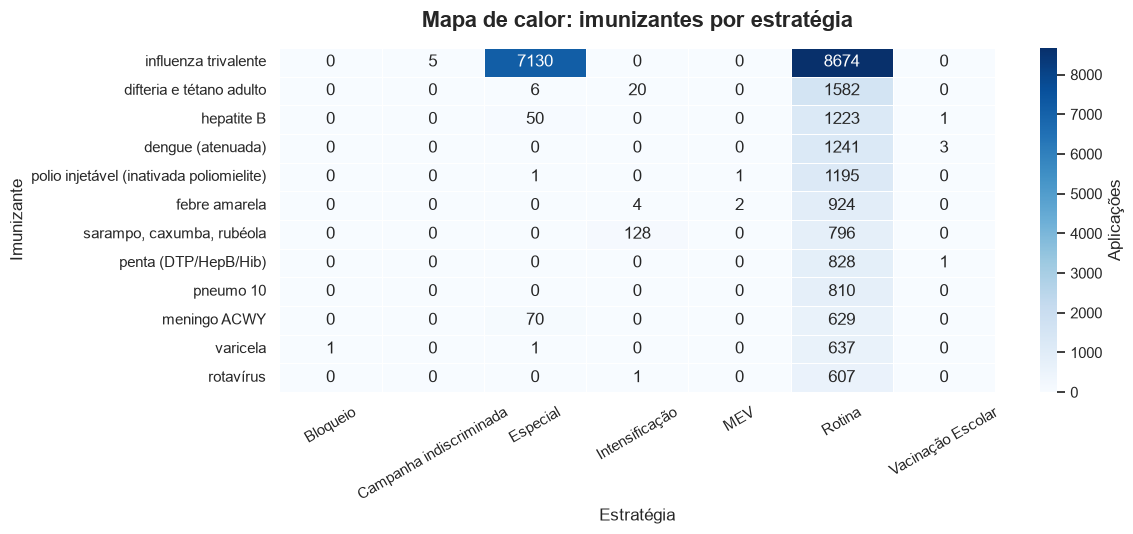

In [13]:
heatmap = pd.crosstab(df["nome_da_vacina"], df["estrategia"], dropna=False)
top_nomes = vacinas.head(12)["Vacina_original"].tolist()
heatmap = heatmap.reindex(index=[v for v in top_nomes if v in heatmap.index], fill_value=0)
heatmap = heatmap.loc[heatmap.sum(axis=1) > 0, heatmap.sum(axis=0) > 0]
heatmap.index = [rotulo_vacina(v) for v in heatmap.index]
heatmap.columns = [rotulo_estrategia(v) for v in heatmap.columns]

if heatmap.empty:
    print("Não há dados suficientes para gerar o mapa de calor.")
else:
    fig, ax = plt.subplots(figsize=(12, max(5.5, 0.45 * len(heatmap))))
    sns.heatmap(
        heatmap,
        annot=True,
        fmt=".0f",
        cmap="Blues",
        linewidths=0.6,
        linecolor="white",
        cbar_kws={"label": "Aplicações"},
        ax=ax
    )
    ax.set_title("Mapa de calor: imunizantes por estratégia", fontsize=16, fontweight="bold", pad=15)
    ax.set_xlabel("Estratégia")
    ax.set_ylabel("Imunizante")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)
    plt.tight_layout()
    plt.show()

O mapa de calor acima cruza os diferentes imunizantes com as respectivas estratégias de vacinação, permitindo identificar onde se concentram os maiores volumes de aplicação.

*Destaque para a Influenza Trivalente:* A vacina contra a influenza trivalente concentra os maiores volumes absolutos, destacando-se fortemente nas estratégias de Rotina (8.674 aplicações) e Especial (7.130 aplicações).   

*Concentração na Rotina:* A grande maioria dos imunizantes do calendário (como difteria e tétano adulto, hepatite B, dengue, pólio, febre amarela, entre outros) apresenta seus maiores picos de doses concentrados na estratégia de Rotina.

*Ações Pontuais:* Outras estratégias, como Bloqueio, Campanha indiscriminada, Intensificação, MEV e Vacinação Escolar, apresentam ocorrências residuais ou nulas para a maioria das vacinas no período analisado.

In [14]:
principais = vacinas.head(5)["Vacina_original"].tolist()

mensal = (
    df[df["nome_da_vacina"].isin(principais)]
    .groupby(["mes", "nome_da_vacina"])
    .size()
    .unstack(fill_value=0)
)

display(mensal)


nome_da_vacina,Vacina dengue (atenuada),Vacina difteria e tétano adulto,Vacina hepatite B,Vacina influenza trivalente,Vacina polio injetável (inativada poliomielite)
mes,,,,,
2026-02,175,177,97,0,153
2026-03,321,330,303,1805,298
2026-04,239,405,339,5523,239
2026-05,267,335,272,4592,246
2026-06,242,314,237,3102,261


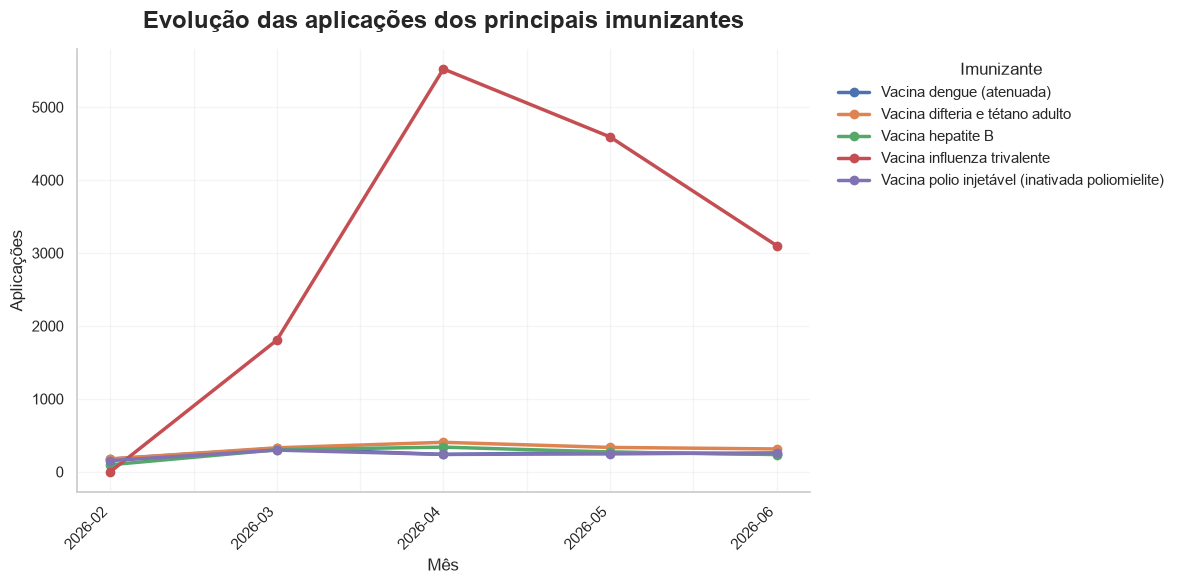

In [15]:
if mensal.empty:
    print("Não há registros suficientes para gerar a evolução mensal.")
else:
    ax = mensal.plot(
        figsize=(12, 6),
        marker="o",
        linewidth=2.5,
        markersize=6
    )

    ax.set_title(
        "Evolução das aplicações dos principais imunizantes",
        fontsize=17,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel("Mês")
    ax.set_ylabel("Aplicações")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.2)

    plt.xticks(rotation=45, ha="right")
    plt.legend(
        title="Imunizante",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=False
    )

    plt.tight_layout()
    plt.show()


O gráfico de linhas acima apresenta a evolução temporal das aplicações mensais para os principais imunizantes entre os meses de fevereiro e junho de 2026.

*Pico Acentuado da Influenza Trivalente:* A vacina de influenza trivalente apresenta uma variação expressiva, registrando um crescimento vertiginoso a partir de março de 2026, atingindo um pico máximo expressivo em abril de 2026 com mais de 5.500 aplicações, seguido de uma redução gradual nos meses seguintes.

*Comportamento Estável dos Demais Imunizantes:* Os demais imunizantes listados como as vacinas contra dengue (atenuada), difteria e tétano adulto, hepatite B e pólio inativada, mantêm patamares estáveis e constantes ao longo de todo o período analisado, com volumes mensais de aplicação situados majoritariamente abaixo de 500 doses.

## Mudança de posição das vacinas ao longo do tempo

,mes,nome_da_vacina,Aplicações,Posição,Vacina
10,2026-02,Vacina difteria e tétano adulto,177,1,difteria e tétano adulto
9,2026-02,Vacina dengue (atenuada),175,2,dengue (atenuada)
23,2026-02,Vacina polio injetável (inativada poliomielite),153,3,polio injetável (inativada poliomielite)
26,2026-02,"Vacina sarampo, caxumba, rubéola",125,4,"sarampo, caxumba, rubéola"
27,2026-02,Vacina varicela,125,4,varicela
11,2026-02,Vacina febre amarela,122,6,febre amarela
18,2026-02,Vacina penta (DTP/HepB/Hib),108,7,penta (DTP/HepB/Hib)
14,2026-02,Vacina hepatite B,97,8,hepatite B
15,2026-02,Vacina meningo ACWY,85,9,meningo ACWY
2,2026-02,Vacina DTP,84,10,DTP


,Posição_mínima,Posição_máxima,Posições_diferentes
nome_da_vacina,,,
Vacina raiva em cultivo celular vero,17,23,5
Vacina pneumo 13,23,37,5
"Vacina vírus sincicial respiratório (recombinante, adjuvada)",25,31,5
Vacina hepatite B,3,8,4
"Vacina sarampo, caxumba, rubéola",4,10,4
Vacina varicela,4,16,4
Vacina pneumo 10,7,11,4
"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",10,21,4
Vacina Vírus Sincicial A e B (recombinante),16,22,4


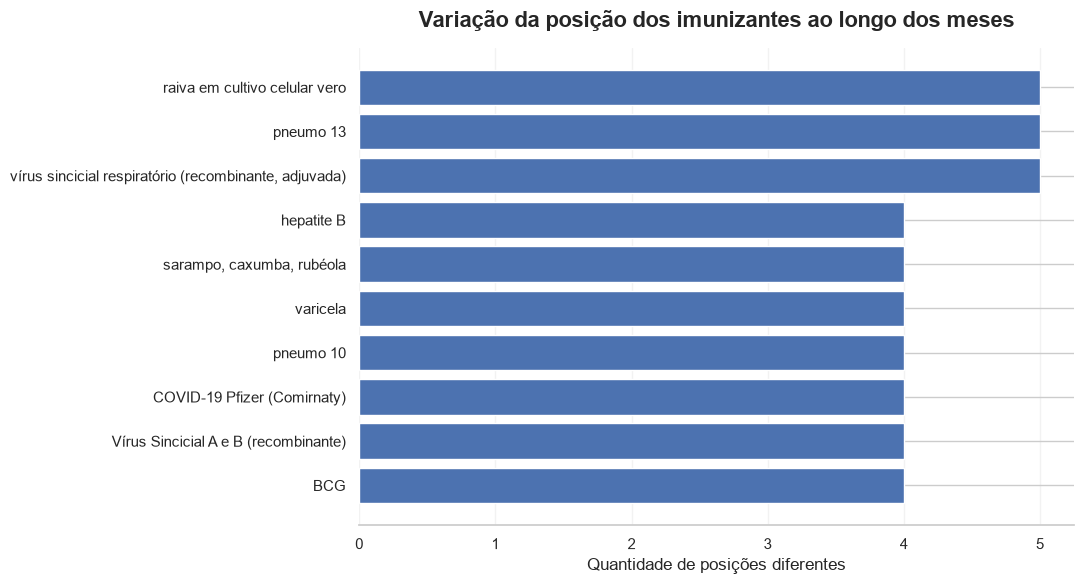

In [16]:
ranking_mensal = (
    df.dropna(subset=["mes"])
    .groupby(["mes", "nome_da_vacina"])
    .size()
    .reset_index(name="Aplicações")
)
ranks = ranking_mensal.groupby("mes")["Aplicações"].rank(method="min", ascending=False)
ranking_mensal["Posição"] = ranks.astype(int)
ranking_mensal["Vacina"] = ranking_mensal["nome_da_vacina"].map(rotulo_vacina)

display(ranking_mensal.sort_values(["mes", "Posição"]).head(30))

variacao_posicao = (
    ranking_mensal.groupby("nome_da_vacina")["Posição"]
    .agg(Posição_mínima="min", Posição_máxima="max", Posições_diferentes="nunique")
    .sort_values(["Posições_diferentes", "Posição_mínima"], ascending=[False, True])
)
display(variacao_posicao.head(15))

variacao_grafico = variacao_posicao.head(10).reset_index()
variacao_grafico["Imunizante"] = variacao_grafico["nome_da_vacina"].map(rotulo_vacina)
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(variacao_grafico["Imunizante"].iloc[::-1], variacao_grafico["Posições_diferentes"].iloc[::-1])
ax.set_title("Variação da posição dos imunizantes ao longo dos meses", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Quantidade de posições diferentes")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()


O gráfico acima apresenta a quantidade de posições diferentes que cada imunizante ocupou no ranking mensal de aplicações ao longo do período analisado.

+*aior Oscilação de Ranking:* Os imunizantes raiva em cultivo celular vero, pneumo 13 e vírus sincicial respiratório (recombinante, adjuvada) registraram a maior volatilidade no período, alternando por 5 posições diferentes no ranking de um mês para o outro.

*Oscilação Moderada:* Em seguida, um grupo composto por vacinas como hepatite B, sarampo, caxumba, rubéola, varicela, pneumo 10, COVID-19 Pfizer (Comirnaty), Vírus Sincicial A e B (recombinante) e BCG apresentou variação constante por 4 posições diferentes na classificação mensal.

## Distribuição anual

,ano,nome_da_vacina,Aplicações,Imunizante
16,2026.0,Vacina dengue (atenuada),1244,dengue (atenuada)
17,2026.0,Vacina difteria e tétano adulto,1561,difteria e tétano adulto
21,2026.0,Vacina hepatite B,1248,hepatite B
23,2026.0,Vacina influenza trivalente,15022,influenza trivalente
32,2026.0,Vacina polio injetável (inativada poliomielite),1197,polio injetável (inativada poliomielite)


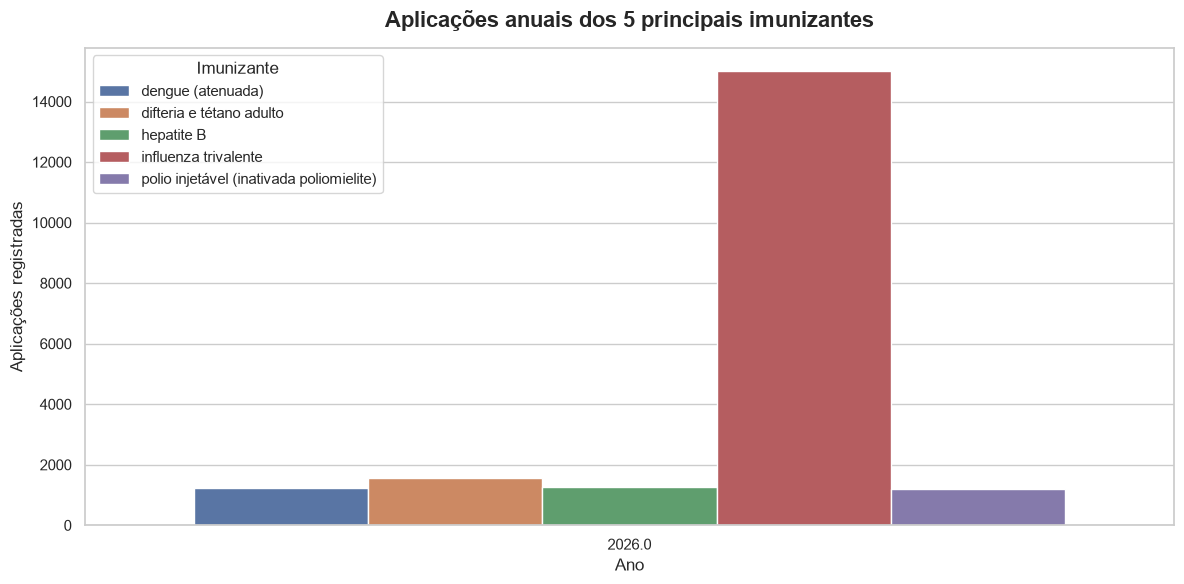

In [17]:
anual = (
    df.dropna(subset=["ano"])
    .groupby(["ano", "nome_da_vacina"])
    .size()
    .reset_index(name="Aplicações")
)

anual_top5 = anual[anual["nome_da_vacina"].isin(principais)].copy()
anual_top5["Imunizante"] = anual_top5["nome_da_vacina"].map(rotulo_vacina)

display(anual_top5)

if anual_top5.empty:
    print("Não há dados anuais suficientes para gerar o gráfico.")
else:
    fig, ax = plt.subplots(figsize=(12, 6))

    sns.barplot(
        data=anual_top5,
        x="ano",
        y="Aplicações",
        hue="Imunizante",
        ax=ax
    )

    ax.set_title(
        "Aplicações anuais dos 5 principais imunizantes",
        fontsize=16,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel("Ano")
    ax.set_ylabel("Aplicações registradas")

    plt.tight_layout()
    plt.show()


O gráfico de barras agrupa o volume de aplicações registradas para os cinco principais imunizantes consolidados ao longo do ano de 2026.

*Destaque Expressivo da Influenza Trivalente:* A vacina de influenza trivalente (representada pela barra vermelha) destaca-se de forma absoluta com um volume que ultrapassa a marca de 14.000 aplicações anuais, refletindo a alta demanda da campanha de vacinação contra a gripe em 2026.

*Demais Imunizantes Principais:* As vacinas de difteria e tétano adulto, hepatite B, dengue (atenuada) e pólio inativada apresentam volumes anuais estáveis e comparáveis entre si, situando-se em patamares próximos na faixa de 1.000 a 1.500 aplicações cada. 

## Distribuição territorial por bairro

In [18]:
colunas_bairro = [
    coluna for coluna in df.columns
    if "bairro" in coluna.lower()
]

print("Colunas relacionadas a bairro:", colunas_bairro)

if not colunas_bairro:
    bairros = pd.DataFrame(columns=["Bairro", "Aplicações", "Percentual (%)"])
    print("A base não possui uma coluna de bairro.")
else:
    coluna_bairro = colunas_bairro[0]

    bairros = (
        df[coluna_bairro]
        .value_counts(dropna=False)
        .rename_axis("Bairro")
        .reset_index(name="Aplicações")
    )

    bairros["Percentual (%)"] = bairros["Aplicações"] / len(df) * 100

    display(bairros.head(15))


Colunas relacionadas a bairro: ['nome_do_bairro']


,Bairro,Aplicações,Percentual (%)
0,Mato Alto Lagoão,4735,15.332060
1,Bom Pastor,4064,13.159343
2,Polícia Rodoviária,3290,10.653110
3,Coloninha,3012,9.752939
4,Jardim Cibele,2317,7.502509
5,Vila São José,2131,6.900236
6,Cidade Alta,1973,6.388628
7,Divineia,1874,6.068063
8,Jardim das Avenidas,1788,5.789593
9,Arapongas,1414,4.578571


## Principais bairros

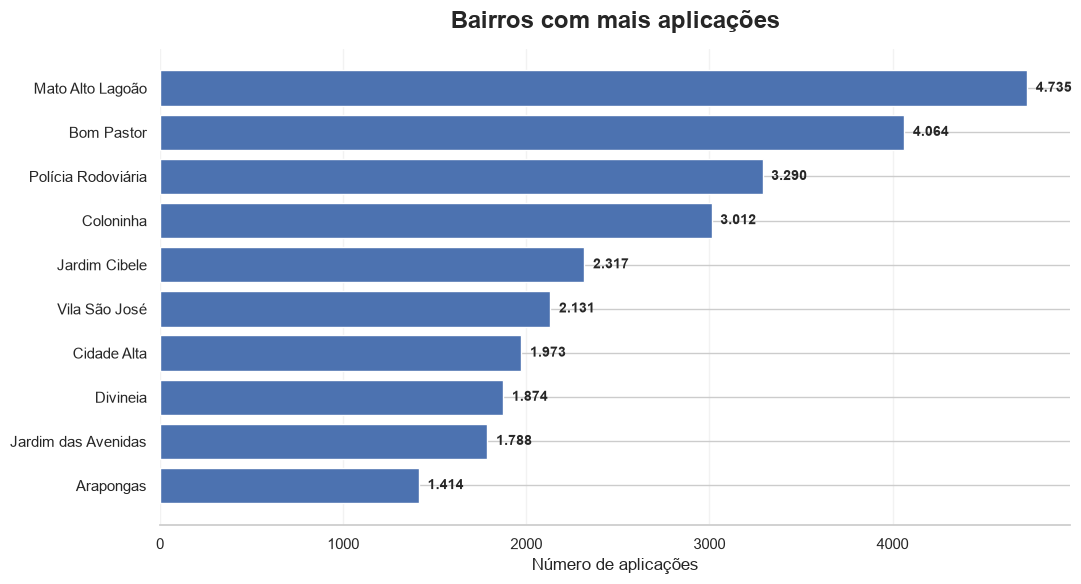

In [19]:
if bairros.empty:
    print("Não há dados de bairro para gerar o gráfico.")
else:
    top_bairros = bairros.head(10).sort_values("Aplicações")

    fig, ax = plt.subplots(figsize=(11, 6))

    bars = ax.barh(
        top_bairros["Bairro"].astype(str),
        top_bairros["Aplicações"]
    )

    ax.set_title(
        "Bairros com mais aplicações",
        fontsize=17,
        fontweight="bold",
        pad=15
    )
    ax.set_xlabel("Número de aplicações")
    ax.set_ylabel("")

    for bar, valor in zip(bars, top_bairros["Aplicações"]):
        ax.text(
            bar.get_width() + top_bairros["Aplicações"].max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{valor:,}".replace(",", "."),
            va="center",
            fontsize=10,
            fontweight="bold"
        )

    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="x", alpha=0.25)

    plt.tight_layout()
    plt.show()


O gráfico acima detalha o volume absoluto de doses aplicadas nos principais bairros do município de Araranguá.   

*Liderança em Doses:* A região combinada de Mato Alto Lagoão lidera de forma destacada o ranking com 4.735 aplicações.

*Principais Regiões de Atendimento:* Logo em seguida, destacam-se os bairros Bom Pastor (4.064 aplicações), Polícia Rodoviária (3.290 aplicações) e Coloninha (3.012 aplicações), formando o grupo de maior volume de atendimento no período.

*Demais Bairros:* O restante do gráfico evidencia a distribuição de doses em localidades como Jardim Cibele (2.317), Vila São José (2.131), Cidade Alta (1.973), Divineia (1.874), Jardim das Avenidas (1.788) e Arapongas (1.414). 

## Distribuição por dose

In [20]:
doses = (
    df["dose"]
    .value_counts(dropna=False)
    .rename_axis("Dose")
    .reset_index(name="Aplicações")
)

doses["Percentual (%)"] = doses["Aplicações"] / len(df) * 100

display(doses.head(15))


,Dose,Aplicações,Percentual (%)
0,ÚNICA,17021,55.114464
1,1ª DOSE,4873,15.778907
2,2ª DOSE,3189,10.326069
3,REFORÇO,2178,7.052424
4,3ª DOSE,1287,4.167341
5,DOSE,1244,4.028106
6,2º REFORÇO,304,0.98436
7,1º REFORÇO,250,0.809507
8,REVACINAÇÃO,217,0.702652
9,PROFILAXIA/TRATAMENTO,101,0.327041


## Principais doses

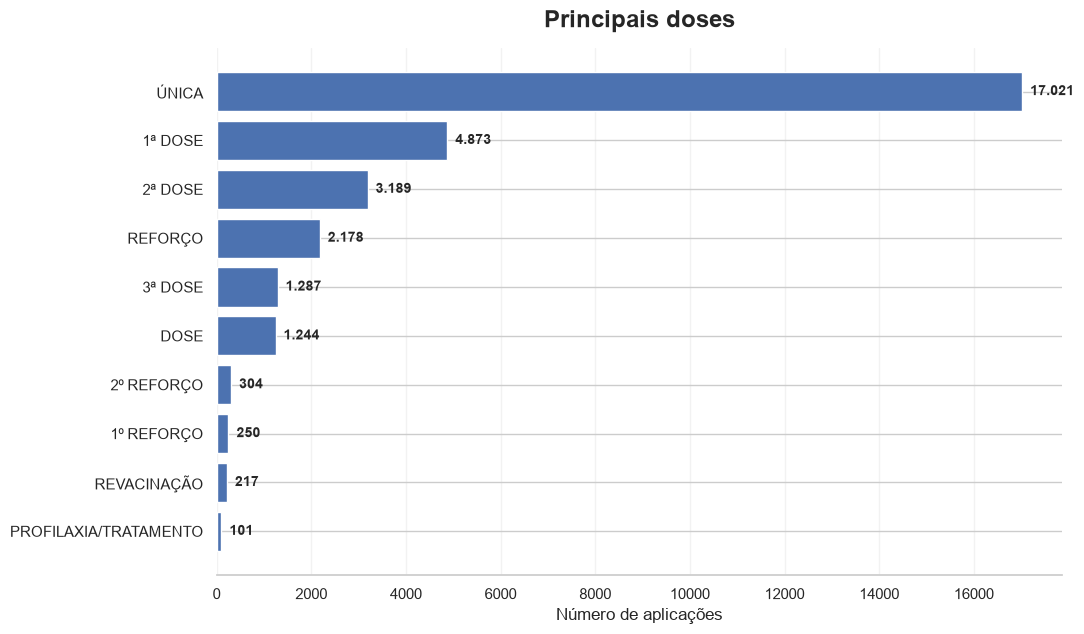

In [21]:
top_doses = doses.head(10).sort_values("Aplicações")

fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.barh(
    top_doses["Dose"].astype(str),
    top_doses["Aplicações"]
)

ax.set_title(
    "Principais doses",
    fontsize=17,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Número de aplicações")
ax.set_ylabel("")

for bar, valor in zip(bars, top_doses["Aplicações"]):
    ax.text(
        bar.get_width() + top_doses["Aplicações"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{valor:,}".replace(",", "."),
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


O gráfico acima detalha a distribuição das aplicações de acordo com a classificação da dose administrada.   

*Destaque para a Dose Única:* A categoria ÚNICA lidera com ampla margem o ranking, registrando 17.021 aplicações.   

*Esquemas Primários:* Em seguida, destacam-se a 1ª DOSE (4.873 aplicações) e a 2ª DOSE (3.189 aplicações), representando a continuidade do esquema vacinal padrão.

*Reforços e Outras Categorias:* O restante do volume é composto por doses de reforço e categorias específicas, como REFORÇO (2.178 aplicações), 3ª DOSE (1.287 aplicações), além de registros de dose genérica, 2º reforço, 1º reforço, revacinação e profilaxia/tratamento. 

## Combinação entre vacina, estratégia e dose

In [22]:
combinacoes = (
    df.groupby(
        ["nome_da_vacina", "estrategia", "dose"],
        dropna=False
    )
    .size()
    .reset_index(name="Aplicações")
    .sort_values("Aplicações", ascending=False)
)

combinacoes["Percentual (%)"] = (
    combinacoes["Aplicações"] / len(df) * 100
)

display(combinacoes.head(20))


,nome_da_vacina,estrategia,dose,Aplicações,Percentual (%)
101,Vacina influenza trivalente,Rotina,ÚNICA,8019,25.965742
98,Vacina influenza trivalente,Especial,ÚNICA,7073,22.902568
46,Vacina dengue (atenuada),Rotina,1ª DOSE,1014,3.283360
59,Vacina difteria e tétano adulto,Rotina,REFORÇO,817,2.645468
83,Vacina hepatite B,Rotina,1ª DOSE,513,1.661108
99,Vacina influenza trivalente,Rotina,1ª DOSE,473,1.531587
25,Vacina HPV quadrivalente,Rotina,ÚNICA,396,1.282259
146,Vacina polio injetável (inativada poliomielite),Rotina,REFORÇO,356,1.152738
175,Vacina varicela,Rotina,2ª DOSE,354,1.146262
164,"Vacina sarampo, caxumba, rubéola",Rotina,1ª DOSE,351,1.136548


## Vacina, estratégia e dose ao longo do tempo

,mes,nome_da_vacina,estrategia,dose,Aplicações,Combinação
14,2026-02,Vacina dengue (atenuada),Rotina,1ª DOSE,174,dengue (atenuada) | Rotina | 1ª DOSE
20,2026-02,Vacina difteria e tétano adulto,Rotina,REFORÇO,98,difteria e tétano adulto | Rotina | REFORÇO
27,2026-02,Vacina hepatite B,Rotina,1ª DOSE,37,hepatite B | Rotina | 1ª DOSE
139,2026-03,Vacina influenza trivalente,Rotina,ÚNICA,1335,influenza trivalente | Rotina | ÚNICA
136,2026-03,Vacina influenza trivalente,Especial,ÚNICA,391,influenza trivalente | Especial | ÚNICA
104,2026-03,Vacina dengue (atenuada),Rotina,1ª DOSE,268,dengue (atenuada) | Rotina | 1ª DOSE
112,2026-03,Vacina difteria e tétano adulto,Rotina,REFORÇO,166,difteria e tétano adulto | Rotina | REFORÇO
126,2026-03,Vacina hepatite B,Rotina,1ª DOSE,100,hepatite B | Rotina | 1ª DOSE
266,2026-04,Vacina influenza trivalente,Rotina,ÚNICA,3917,influenza trivalente | Rotina | ÚNICA
263,2026-04,Vacina influenza trivalente,Especial,ÚNICA,1445,influenza trivalente | Especial | ÚNICA


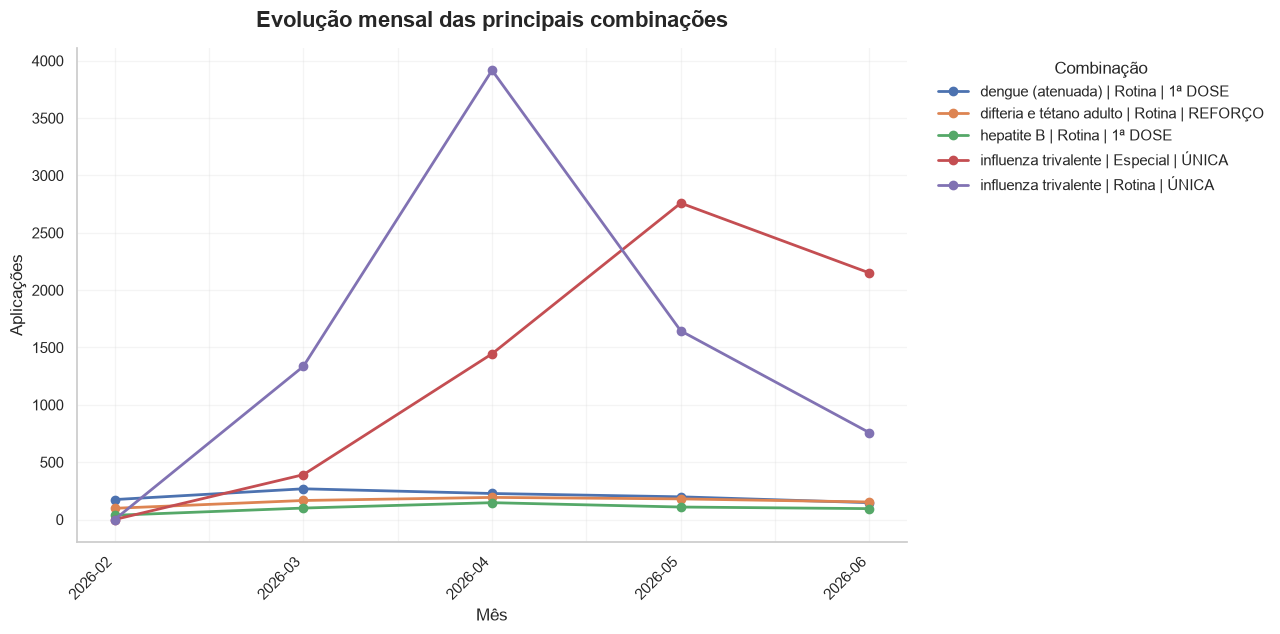

In [23]:
combinacoes_mensais = (
    df.dropna(subset=["mes"])
    .groupby(["mes", "nome_da_vacina", "estrategia", "dose"], dropna=False)
    .size().reset_index(name="Aplicações")
)
chaves_top = (
    combinacoes_mensais.groupby(["nome_da_vacina", "estrategia", "dose"])["Aplicações"]
    .sum().sort_values(ascending=False).head(5).index
)
top_mensais = combinacoes_mensais[combinacoes_mensais.set_index(["nome_da_vacina", "estrategia", "dose"]).index.isin(chaves_top)].copy()
top_mensais["Combinação"] = (top_mensais["nome_da_vacina"].map(rotulo_vacina) + " | " + top_mensais["estrategia"].fillna("Não informado") + " | " + top_mensais["dose"].fillna("Não informado"))
display(top_mensais.sort_values(["mes", "Aplicações"], ascending=[True, False]).head(30))

serie_combinacoes = top_mensais.pivot_table(index="mes", columns="Combinação", values="Aplicações", aggfunc="sum", fill_value=0)
if not serie_combinacoes.empty:
    ax = serie_combinacoes.plot(figsize=(13, 6.5), marker="o", linewidth=2)
    ax.set_title("Evolução mensal das principais combinações", fontsize=16, fontweight="bold", pad=15)
    ax.set_xlabel("Mês")
    ax.set_ylabel("Aplicações")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.2)
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Combinação", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    plt.tight_layout()
    plt.show()


O gráfico de linhas acima apresenta a trajetória temporal das principais combinações cruzando imunizante, estratégia de vacinação e tipo de dose entre fevereiro e junho de 2026.

* **Pico da Influenza Trivalente na Rotina:** A combinação de **influenza trivalente | Rotina | ÚNICA** (representada pela linha roxa) registra o volume mais expressivo de todo o período, disparando acentuadamente em março e atingindo um pico máximo próximo a 4.000 aplicações em abril de 2026, antes de desacelerar nos meses seguintes.
* **Destaque da Estratégia Especial:** A combinação **influenza trivalente | Especial | ÚNICA** (linha vermelha) também exibe um crescimento vertiginoso a partir de março, alcançando o seu ponto máximo em maio de 2026 com cerca de 2.750 aplicações.
* **Comportamento Constante das Demais Combinações:** As demais combinações mapeadas — como **dengue (atenuada) | Rotina | 1ª DOSE**, **difteria e tétano adulto | Rotina | REFORÇO** e **hepatite B | Rotina | 1ª DOSE** — mantêm-se em patamares estáveis e contínuos ao longo dos meses, com volumes mensais situados abaixo de 500 aplicações.

## Conferência de códigos e nomes das vacinas

In [24]:
if "codigo_da_vacina" not in df.columns:
    print("A coluna codigo_da_vacina não está disponível na base.")
else:
    codigos_vacinas = (
        df[["codigo_da_vacina", "nome_da_vacina"]]
        .drop_duplicates()
        .sort_values(["codigo_da_vacina", "nome_da_vacina"])
    )

    display(codigos_vacinas)

    conflitos = (
        codigos_vacinas
        .groupby("codigo_da_vacina")["nome_da_vacina"]
        .nunique()
        .loc[lambda serie: serie > 1]
    )

    print("Códigos associados a mais de um nome:", len(conflitos))

    if len(conflitos) > 0:
        display(
            codigos_vacinas[
                codigos_vacinas["codigo_da_vacina"].isin(conflitos.index)
            ]
        )


,codigo_da_vacina,nome_da_vacina
342,9,Vacina hepatite B
283,14,Vacina febre amarela
1519,15,Vacina BCG
1929,17,Vacina Hib
4913,21,Vacina pneumo 23
22275,22,Vacina polio injetável
1222,22,Vacina polio injetável (inativada poliomielite)
1325,24,"Vacina sarampo, caxumba, rubéola"
21750,24,"Vacina sarampo, caxumba, rubéola (24) - Rotina (1) - 1ª DOSE"
21751,24,"Vacina sarampo, caxumba, rubéola (24) - Rotina (1) - 2ª DOSE"


Códigos associados a mais de um nome: 7


,codigo_da_vacina,nome_da_vacina
22275,22,Vacina polio injetável
1222,22,Vacina polio injetável (inativada poliomielite)
1325,24,"Vacina sarampo, caxumba, rubéola"
21750,24,"Vacina sarampo, caxumba, rubéola (24) - Rotina (1) - 1ª DOSE"
21751,24,"Vacina sarampo, caxumba, rubéola (24) - Rotina (1) - 2ª DOSE"
22264,42,Vacina penta
1142,42,Vacina penta (DTP/HepB/Hib)
21867,87,Vacina COVID
0,87,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)"
21871,102,Vacina COVID


## Preservação de apresentações próximas

,Imunizante,Aplicações
0,COVID-19 Pfizer (Comirnaty),419
1,COVID-19 Pfizer (Comirnaty) pediátrica menor de 5 anos,328
2,COVID,5
3,COVID-19 Pfizer (Comirnaty) pediátrica menor de,1


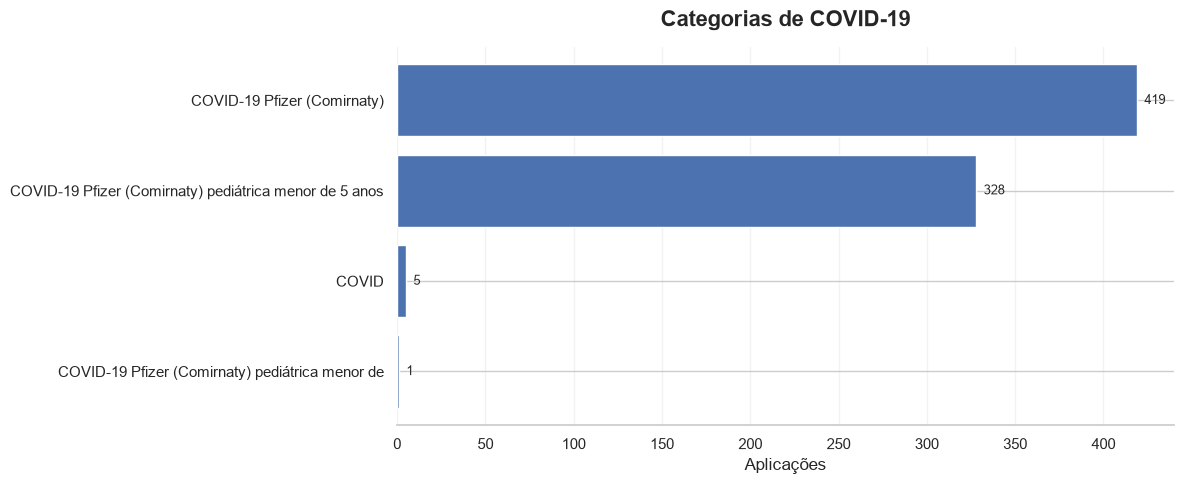

,Imunizante,Aplicações
0,"NIRSEVIMABE 0,5ml",84
1,"NIRSEVIMABE 1,0ml",21


,Imunizante + estratégia + dose,Aplicações,Percentual (%)
0,Vacina influenza trivalente (33) - Rotina (1) - ÚNICA (9),8019,25.965742
1,Vacina influenza trivalente (33) - Especial (2) - ÚNICA (9),7073,22.902568
2,Vacina dengue (atenuada) (104) - Rotina (1) - 1ª DOSE (1),1026,3.322216
3,Vacina difteria e tétano adulto (25) - Rotina (1) - REFORÇO (38),817,2.645468
4,Vacina hepatite B (9) - Rotina (1) - 1ª DOSE (1),513,1.661108
5,Vacina influenza trivalente (33) - Rotina (1) - 1ª DOSE (1),473,1.531587
6,Vacina HPV quadrivalente (67) - Rotina (1) - ÚNICA (9),396,1.282259
7,Vacina polio injetável (inativada poliomielite) (22) - Rotina (1) - REFORÇO (38),365,1.181880
8,Vacina varicela (34) - Rotina (1) - 2ª DOSE (2),354,1.146262
9,"Vacina sarampo, caxumba, rubéola (24) - Rotina (1) - 1ª DOSE (1)",349,1.130072


In [25]:
covid_mask = df["nome_da_vacina"].astype("string").str.contains("COVID", case=False, na=False)
covid = (
    df.loc[covid_mask, "nome_da_vacina"]
    .value_counts(dropna=False)
    .rename_axis("Vacina_original")
    .reset_index(name="Aplicações")
)
covid["Imunizante"] = covid["Vacina_original"].map(rotulo_vacina)

display(covid[["Imunizante", "Aplicações"]])

if not covid.empty:
    dados = covid.sort_values("Aplicações")
    fig, ax = plt.subplots(figsize=(12, max(5, 0.55 * len(dados))))
    bars = ax.barh(dados["Imunizante"], dados["Aplicações"])
    ax.set_title("Categorias de COVID-19", fontsize=16, fontweight="bold", pad=15)
    ax.set_xlabel("Aplicações")
    ax.set_ylabel("")
    limite = max(dados["Aplicações"].max(), 1)
    for bar, valor in zip(bars, dados["Aplicações"]):
        ax.text(bar.get_width() + limite * 0.01, bar.get_y() + bar.get_height()/2, f"{valor:,}".replace(",", "."), va="center", fontsize=9)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

nirsevimabe = (
    df.loc[df["nome_da_vacina"].astype("string").str.contains("NIRSEVIMABE", case=False, na=False), "nome_da_vacina"]
    .value_counts(dropna=False)
    .rename_axis("Vacina_original")
    .reset_index(name="Aplicações")
)
nirsevimabe["Imunizante"] = nirsevimabe["Vacina_original"].map(rotulo_vacina)
display(nirsevimabe[["Imunizante", "Aplicações"]])

if "vacina_estrategia_e_dose" in df.columns:
    apresentacoes = df["vacina_estrategia_e_dose"].value_counts(dropna=False).rename_axis("Imunizante + estratégia + dose").reset_index(name="Aplicações")
    apresentacoes["Percentual (%)"] = apresentacoes["Aplicações"] / len(df) * 100
    display(apresentacoes.head(20))
else:
    apresentacoes = pd.DataFrame()
    print("A coluna vacina_estrategia_e_dose não está disponível na base.")

O gráfico acima detalha a distribuição das aplicações segmentadas pelas diferentes categorias específicas de vacinas contra a COVID-19.

* **Destaque para a Comirnaty Adulta:** A categoria **COVID-19 Pfizer (Comirnaty)** lidera o ranking com **419 aplicações** registradas no período.
* **Público Pediátrico:** Logo em seguida, a versão **COVID-19 Pfizer (Comirnaty) pediátrica menor de 5 anos** destaca-se com **328 aplicações**.
* **Demais Registros:** As categorias residuais — apresentadas como **COVID** (5 aplicações) e **COVID-19 Pfizer (Comirnaty) pediátrica menor de** (1 aplicação) — possuem volumes expressivamente menores ou registram dados parciais.

## Comparação entre imunizantes por diferentes recortes

,Imunizante,Estratégia,Aplicações,Percentual dentro do imunizante (%)
0,dengue (atenuada),Rotina,1241,99.758842
1,dengue (atenuada),Vacinação Escolar,3,0.241158
4,difteria e tétano adulto,Rotina,1582,98.383085
3,difteria e tétano adulto,Intensificação,20,1.243781
2,difteria e tétano adulto,Especial,6,0.373134
7,febre amarela,Rotina,924,99.354839
5,febre amarela,Intensificação,4,0.430108
6,febre amarela,MEV,2,0.215054
9,hepatite B,Rotina,1223,95.996860
8,hepatite B,Especial,50,3.924647


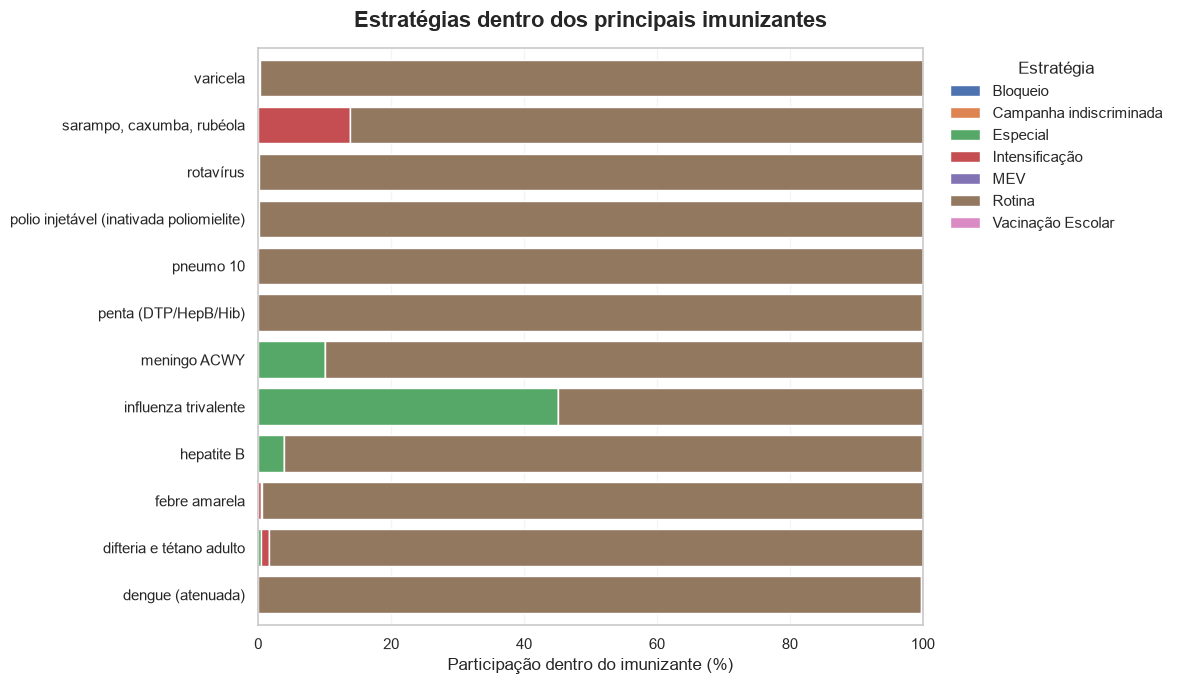

In [26]:
top12 = vacinas.head(12)["Vacina_original"].tolist()
recorte_estrategia = (
    df[df["nome_da_vacina"].isin(top12)]
    .groupby(["nome_da_vacina", "estrategia"], dropna=False)
    .size().reset_index(name="Aplicações")
)
recorte_estrategia["Percentual dentro do imunizante (%)"] = (
    recorte_estrategia["Aplicações"] /
    recorte_estrategia.groupby("nome_da_vacina")["Aplicações"].transform("sum") * 100
)
recorte_estrategia["Imunizante"] = recorte_estrategia["nome_da_vacina"].map(rotulo_vacina)
recorte_estrategia["Estratégia"] = recorte_estrategia["estrategia"].map(rotulo_estrategia)

display(recorte_estrategia[["Imunizante", "Estratégia", "Aplicações", "Percentual dentro do imunizante (%)"]].sort_values(["Imunizante", "Aplicações"], ascending=[True, False]))

grafico_estrategia = recorte_estrategia.pivot_table(index="Imunizante", columns="Estratégia", values="Percentual dentro do imunizante (%)", aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(12, 7))
grafico_estrategia.plot(kind="barh", stacked=True, ax=ax, width=0.78)
ax.set_title("Estratégias dentro dos principais imunizantes", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Participação dentro do imunizante (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.2)
ax.legend(title="Estratégia", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

O gráfico acima apresenta a participação percentual das diferentes estratégias de vacinação dentro de cada um dos principais imunizantes analisados.

* **Predominância da Rotina:** Para a grande maioria dos imunizantes listados, como dengue (atenuada), difteria e tétano adulto, febre amarela, hepatite B, pneumo 10, pólio inativada, rotavírus e varicela, a estratégia de **Rotina** (barra marrom) representa praticamente 100% das aplicações.
* **Participação da Estratégia Especial:** O imunizante de **influenza trivalente** destaca-se por apresentar uma divisão expressiva, com uma fatia considerável concentrada na estratégia **Especial** (barra verde), além da rotina. A estratégia especial também aparece com menor proporção em meningo ACW.
* **Outras Estratégias:** A modalidade de **Intensificação** (barra vermelha) surge de forma pontual e minoritária na composição das aplicações de sarampo, caxumba e rubéola, bem como em difteria e tétano adulto.

## Aplicações e pessoas

Possíveis identificadores de pessoa: []
Total de aplicações registradas: 30.883
Não foi identificado um campo de pessoa. O total abaixo representa aplicações registradas, não pessoas únicas.


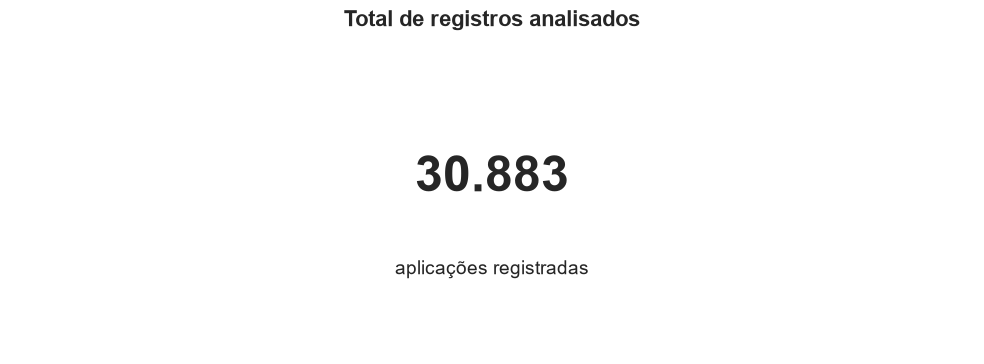

In [27]:
possiveis_identificadores = [
    coluna for coluna in df.columns
    if any(
        termo in coluna.lower()
        for termo in ["cpf", "cns", "id_pessoa", "id_paciente", "paciente", "pessoa"]
    )
]

total_aplicacoes = len(df)

print("Possíveis identificadores de pessoa:", possiveis_identificadores)
print(f"Total de aplicações registradas: {total_aplicacoes:,}".replace(",", "."))

# Um gráfico com uma única barra não acrescenta informação.
# Quando não existe identificador de pessoa, apresentamos o total como indicador visual.
if possiveis_identificadores:
    identificador = possiveis_identificadores[0]
    pessoas_distintas = df[identificador].nunique(dropna=True)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

    indicadores = [
        ("Aplicações registradas", total_aplicacoes),
        ("Pessoas distintas", pessoas_distintas),
    ]

    for ax, (titulo, valor) in zip(axes, indicadores):
        ax.text(
            0.5, 0.55,
            f"{valor:,}".replace(",", "."),
            ha="center",
            va="center",
            fontsize=28,
            fontweight="bold"
        )
        ax.text(
            0.5, 0.25,
            titulo,
            ha="center",
            va="center",
            fontsize=12
        )
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.axis("off")

    fig.suptitle(
        "Resumo da população registrada",
        fontsize=16,
        fontweight="bold",
        y=0.98
    )
    plt.tight_layout()
    plt.show()

else:
    print(
        "Não foi identificado um campo de pessoa. "
        "O total abaixo representa aplicações registradas, não pessoas únicas."
    )

    fig, ax = plt.subplots(figsize=(10, 3.8))

    ax.text(
        0.5, 0.58,
        f"{total_aplicacoes:,}".replace(",", "."),
        ha="center",
        va="center",
        fontsize=36,
        fontweight="bold"
    )
    ax.text(
        0.5, 0.28,
        "aplicações registradas",
        ha="center",
        va="center",
        fontsize=14
    )

    ax.set_title(
        "Total de registros analisados",
        fontsize=16,
        fontweight="bold",
        pad=18
    )
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    plt.tight_layout()
    plt.show()


## Síntese dos resultados

Total de aplicações analisadas: 30.883
Quantidade de imunizantes: 41
Quantidade de estratégias: 10
Imunizante mais frequente: influenza trivalente
Participação do imunizante mais frequente: 51.2%
Participação acumulada dos 5 principais imunizantes: 68.4%
Participação acumulada dos 10 principais imunizantes: 82.0%
Quantidade de bairros: 15
Período analisado: 2026-02-01 00:00:00 até 2026-06-30 00:00:00


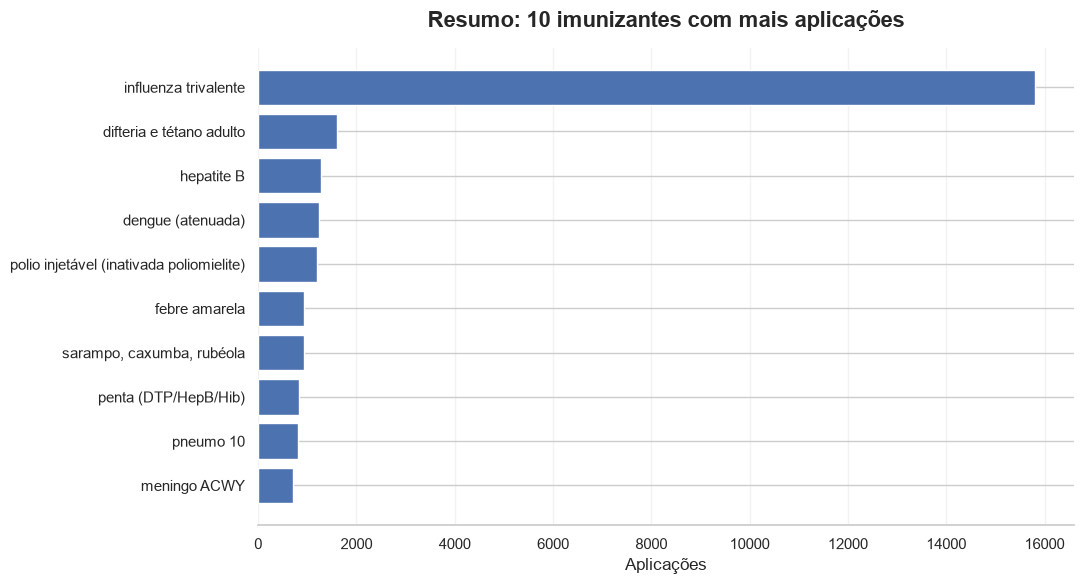

In [28]:
total_aplicacoes = len(df)
quantidade_imunizantes = df["nome_da_vacina"].nunique()
quantidade_estrategias = df["estrategia"].nunique()
imunizante_principal = vacinas.iloc[0]["Imunizante"]
participacao_principal = vacinas.iloc[0]["Percentual (%)"]
participacao_top5 = vacinas.head(5)["Percentual (%)"].sum()
participacao_top10 = vacinas.head(10)["Percentual (%)"].sum()

print(f"Total de aplicações analisadas: {total_aplicacoes:,}".replace(",", "."))
print(f"Quantidade de imunizantes: {quantidade_imunizantes}")
print(f"Quantidade de estratégias: {quantidade_estrategias}")
print(f"Imunizante mais frequente: {imunizante_principal}")
print(f"Participação do imunizante mais frequente: {participacao_principal:.1f}%")
print(f"Participação acumulada dos 5 principais imunizantes: {participacao_top5:.1f}%")
print(f"Participação acumulada dos 10 principais imunizantes: {participacao_top10:.1f}%")

if not bairros.empty:
    print(f"Quantidade de bairros: {df[coluna_bairro].nunique(dropna=True)}")
else:
    print("Quantidade de bairros: não disponível")

print(f"Período analisado: {df['data_da_aplicacao'].min()} até {df['data_da_aplicacao'].max()}")

resumo_grafico = vacinas.head(10).sort_values("Aplicações")
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(resumo_grafico["Imunizante"], resumo_grafico["Aplicações"])
ax.set_title("Resumo: 10 imunizantes com mais aplicações", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Aplicações")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()


## Respostas às perguntas orientadoras

1. Quais vacinas mais se destacam e por quais medidas?


,Imunizante,Aplicações,Percentual (%)
0,influenza trivalente,15809,51.189975
1,difteria e tétano adulto,1608,5.206748
2,hepatite B,1274,4.125247
3,dengue (atenuada),1244,4.028106
4,polio injetável (inativada poliomielite),1197,3.875919
5,febre amarela,930,3.011365
6,"sarampo, caxumba, rubéola",924,2.991937
7,penta (DTP/HepB/Hib),829,2.684325
8,pneumo 10,810,2.622802
9,meningo ACWY,699,2.263381


2. A posição das vacinas muda conforme o período?


,Posição_mínima,Posição_máxima,Posições_diferentes
nome_da_vacina,,,
Vacina raiva em cultivo celular vero,17,23,5
Vacina pneumo 13,23,37,5
"Vacina vírus sincicial respiratório (recombinante, adjuvada)",25,31,5
Vacina hepatite B,3,8,4
"Vacina sarampo, caxumba, rubéola",4,10,4
Vacina varicela,4,16,4
Vacina pneumo 10,7,11,4
"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",10,21,4
Vacina Vírus Sincicial A e B (recombinante),16,22,4


3. A base se concentra em poucos imunizantes ou se distribui de forma mais equilibrada?
Os 5 primeiros imunizantes representam 68.4% dos registros.
Os 10 primeiros imunizantes representam 82.0% dos registros.
4. As apresentações próximas permanecem diferenciadas?
Foram identificadas 163 combinações distintas de vacina, estratégia e dose.
5. Como estratégia e dose modificam a leitura da distribuição?


,nome_da_vacina,estrategia,Aplicações,Percentual dentro do imunizante (%),Imunizante,Estratégia
13,Vacina influenza trivalente,Rotina,8674,54.867481,influenza trivalente,Rotina
12,Vacina influenza trivalente,Especial,7130,45.100892,influenza trivalente,Especial
4,Vacina difteria e tétano adulto,Rotina,1582,98.383085,difteria e tétano adulto,Rotina
0,Vacina dengue (atenuada),Rotina,1241,99.758842,dengue (atenuada),Rotina
9,Vacina hepatite B,Rotina,1223,95.996860,hepatite B,Rotina
21,Vacina polio injetável (inativada poliomielite),Rotina,1195,99.832916,polio injetável (inativada poliomielite),Rotina
7,Vacina febre amarela,Rotina,924,99.354839,febre amarela,Rotina
16,Vacina penta (DTP/HepB/Hib),Rotina,828,99.879373,penta (DTP/HepB/Hib),Rotina
18,Vacina pneumo 10,Rotina,810,100.000000,pneumo 10,Rotina
25,"Vacina sarampo, caxumba, rubéola",Rotina,796,86.147186,"sarampo, caxumba, rubéola",Rotina


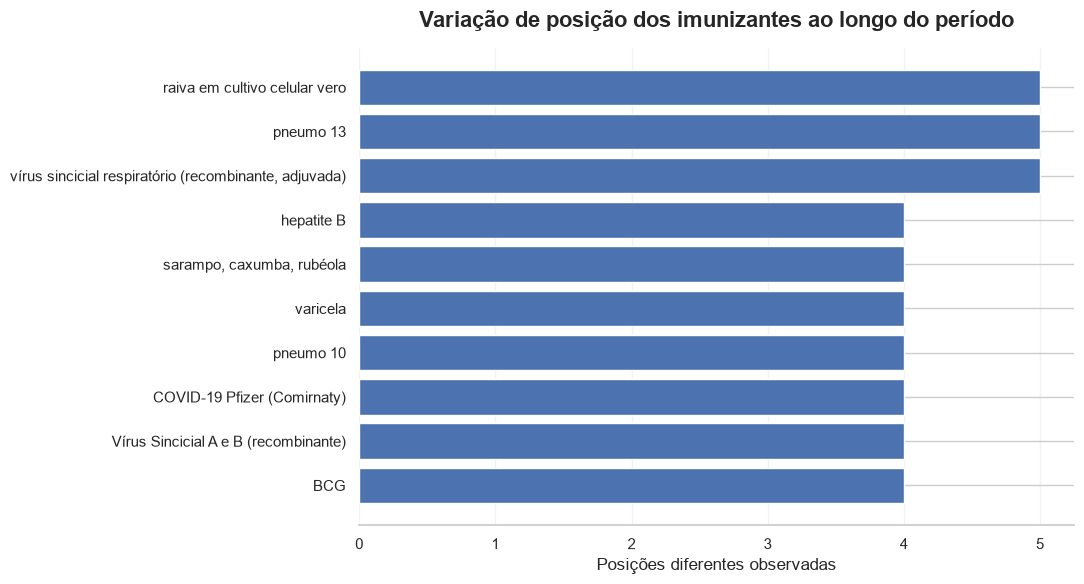

In [29]:
print("1. Quais vacinas mais se destacam e por quais medidas?")
display(vacinas.head(10)[["Imunizante", "Aplicações", "Percentual (%)"]])

print("2. A posição das vacinas muda conforme o período?")
display(variacao_posicao.head(10))

print("3. A base se concentra em poucos imunizantes ou se distribui de forma mais equilibrada?")
print(f"Os 5 primeiros imunizantes representam {participacao_top5:.1f}% dos registros.")
print(f"Os 10 primeiros imunizantes representam {participacao_top10:.1f}% dos registros.")

print("4. As apresentações próximas permanecem diferenciadas?")
if "vacina_estrategia_e_dose" in df.columns:
    print(f"Foram identificadas {len(apresentacoes)} combinações distintas de vacina, estratégia e dose.")
else:
    print("A coluna específica de combinação não está disponível; a diferenciação foi analisada pelas colunas individuais.")

print("5. Como estratégia e dose modificam a leitura da distribuição?")
display(recorte_estrategia.sort_values("Aplicações", ascending=False).head(20))

if not variacao_posicao.empty:
    dados = variacao_posicao.head(10).reset_index()
    dados["Imunizante"] = dados["nome_da_vacina"].map(rotulo_vacina)
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.barh(dados["Imunizante"].iloc[::-1], dados["Posições_diferentes"].iloc[::-1])
    ax.set_title("Variação de posição dos imunizantes ao longo do período", fontsize=16, fontweight="bold", pad=15)
    ax.set_xlabel("Posições diferentes observadas")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.25)
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout()
    plt.show()


## Limitações

- Os registros representam aplicações, não necessariamente pessoas únicas.
- A frequência de aplicações não representa, sozinha, cobertura vacinal.
- Os resultados dependem do período e da qualidade dos dados disponíveis.
- A análise descreve a distribuição dos registros e não mede eficácia clínica dos imunizantes.
- Bairro e sala de vacinação não são considerados equivalentes.
- Quando uma variável específica não está presente na base, a análise correspondente não é inventada ou substituída por outra variável.

## Conclusão

A análise exploratória da base `vacinas_analitico.csv` permite identificar com precisão o panorama da imunização, destacando volumes, concentrações e padrões territoriais e temporais no período analisado.

Os resultados evidenciam uma forte concentração nos registros: a vacina **influenza trivalente** lidera de forma absoluta o ranking com **15.809 aplicações** (representando **51,2%** do total de participação), impulsionada fortemente por um pico em abril de 2026 que ultrapassou **5.500 aplicações mensais**. Em contrapartida, os demais imunizantes mantêm volumes mensais estáveis abaixo de 500 doses. No acumulado anual dos principais imunizantes, a influenza destaca-se com mais de **14.000 doses**, enquanto imunizantes como difteria e tétano adulto, hepatite B, dengue atenuada e pólio inativada situam-se na faixa de 1.000 a 1.500 aplicações cada.

Em termos de estratégias e tipos de doses, a modalidade de **Rotina** sobressai-se com **22.648 aplicações**, seguida por campanhas **Especiais** com **7.791 aplicações**. O cruzamento desses dados demonstra que a influenza trivalente concentra seus maiores volumes tanto na rotina (**8.674 aplicações**) quanto na estratégia especial (**7.130 aplicações**). Quanto à tipologia das doses aplicadas, a categoria **ÚNICA** lidera expressivamente com **17.021 registros**, seguida pela **1ª DOSE** (4.873) e **2ª DOSE** (3.189).

No recorte territorial, a distribuição por bairros no município de Araranguá aponta a região combinada de **Mato Alto Lagoão** na liderança com **4.735 aplicações** (**15,33%**), seguida de perto pelo **Bom Pastor** (4.064 doses / **13,16%**) e pela **Polícia Rodoviária** (3.290 doses / **10,65%**). 

Dessa forma, os resultados confirmam que as dimensões de período, estratégia, dose e território efetivamente disponíveis no arquivo estruturam um cenário de alta concentração em campanhas sazonais específicas, mantendo a estabilidade nos demais atendimentos de rotina e cobertura territorial.